![Token-Gated Language Models](https://raw.githubusercontent.com/token-gate-llms/TokenGate/main/assets/title.png)

[![GitHub](https://img.shields.io/badge/GitHub-TokenGate-181717?logo=github&logoColor=white)](https://github.com/token-gate-llms/TokenGate) [![arXiv](https://img.shields.io/badge/arXiv-2610.26754-B31B1B?logo=arxiv&logoColor=white)](https://arxiv.org/abs/2610.26754) [![Hugging Face](https://img.shields.io/badge/%F0%9F%A4%97-TokenGate-FFD21E)](https://huggingface.co/papers/2610.26754) [![X](https://img.shields.io/badge/X-Launch%20thread-000000?logo=x&logoColor=white)](https://x.com/lianapatel_/status/2112924355240099875)

TokenGate extends existing trained models with learned token selection. **Token-Gated Language Models selectively process the context that matters**, reaching up to **11.3× faster prefill** and **3.4× lower peak memory** at matched accuracy in [our paper](https://arxiv.org/abs/2610.26754). It brings conditional computation, akin to MoE layers, to a different scaling dimension: context tokens.

# Let's make LLM prefill faster. 📖⚡

In this notebook we will:

1. **Set the test:** bury one fact in a long [needle-in-a-haystack](https://github.com/gkamradt/needle-in-a-haystack) document and ask for it.
2. **Compare standard and TokenGate prefill:** run both on the same prompt, compare answers and TTFT, and inspect the tokens TokenGate kept. 🏅
3. **Make your model a Token-Gated Language Model:** optionally train a gate and a separate LoRA comparison model on four A100 GPUs. 😎

The guided inference path fits a free Colab T4; the optional full training path needs four A100 GPUs.


## How TokenGate works

TokenGate is a small, drop-in component that extends existing trained models with end-to-end learned token pruning and lightweight adaptation. A gate at an early layer selects document tokens for continued processing while keeping the question and instructions available.

![Standard Model Prefill beside TokenGate Prefill](https://raw.githubusercontent.com/token-gate-llms/TokenGate/2577e0968933496b741b248762b6169791790325/demo/assets/tokengate_explainer.gif)

Across retrieval, code completion, extraction, multi-hop QA, and summarization, our paper reports stronger accuracy–efficiency tradeoffs than standard full prefill and other pruning or sparse attention methods. 🔥
More details are in [our paper](https://arxiv.org/abs/2610.26754).

<table><tr><td width="100%" valign="top"><img src="https://raw.githubusercontent.com/token-gate-llms/TokenGate/2577e0968933496b741b248762b6169791790325/demo/assets/tokengate_results_annotated.png" width="100%" alt="Accuracy versus time to first token and peak prefill memory across five tasks"></td></tr></table>


## 1. Setting up a needle-in-a-haystack question

We use a [needle-in-a-haystack (NIAH)](https://github.com/gkamradt/needle-in-a-haystack) task: one sentence about an activity in a city is planted among unrelated essays. The model must find that sentence to answer a short question. The default example puts the needle near the middle of a roughly 4k-token document; later, you can try other depths and lengths.


In [1]:
#@title Runtime and model { display-mode: "form" }
MODEL = 'Qwen3-1.7B' #@param ['Qwen3-1.7B', 'Qwen3.5-2B']
GPU_RUNTIME = 'T4' #@param ['T4', 'A100']

BASE_MODELS = {'Qwen3-1.7B':'Qwen/Qwen3-1.7B', 'Qwen3.5-2B':'Qwen/Qwen3.5-2B'}
CHECKPOINTS = {'Qwen3-1.7B':('liana313/tokengate-niah-qwen3-1.7b','3ef4d84ebd161a9700acced6e92f7cd5c50225ad'),
               'Qwen3.5-2B':('liana313/tokengate-niah-qwen3.5-2b','b1fe3e72b9896efc821fbfa02a19fcded4de6d77')}
# Published full-prefill LoRA controls paired with the two released gates.
SFT_BASELINES = {
    'Qwen3-1.7B': ('liana313/tokengate-sftbase-niah-qwen3-1.7b',
                    '9a9703694aed601721414c3f8a6db7d9c83650c0', 'lora_step10200.pt'),
    'Qwen3.5-2B': ('liana313/tokengate-sftbase-niah-qwen3.5-2b',
                   '372728b32e8819964ec00279b1f45a64c803170d', 'lora_step600.pt'),
}
BASE_MODEL = BASE_MODELS[MODEL]
EXAMPLE_INDEX = 1  # middle-depth Hanoi example
DOC_TOKENS = 4096
print('Default run:', MODEL, '| middle-depth example | 4k document | GPU:', GPU_RUNTIME)


Default run: Qwen3-1.7B | middle-depth example | 4k document | GPU: T4


In [2]:
#@title Set up the demo environment { display-mode: "form" }
import gc, importlib, subprocess, sys
from pathlib import Path
from IPython.utils.io import capture_output

# Get the current demo code (Colab) or use this checkout (local/A100).
SOURCE = (Path('/content/TokenGate') if Path('/content').is_dir()
          else Path.cwd().parent if Path.cwd().name == 'demo' else Path.cwd())
if Path('/content').is_dir():
    if SOURCE.exists():
        subprocess.run(['git', '-C', str(SOURCE), 'fetch', '-q', 'origin', 'tokengate_demo'], check=True)
        subprocess.run(['git', '-C', str(SOURCE), 'switch', '-q', '-C', 'tokengate_demo', 'origin/tokengate_demo'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', '-b', 'tokengate_demo',
                        'https://github.com/token-gate-llms/TokenGate', str(SOURCE)], check=True)

# Install dependencies and load the latest helper code in this runtime.
sys.path[:0] = [str(SOURCE), str(SOURCE/'demo')]
for name in list(sys.modules):
    if name in ('tokengate', 'demo_helpers') or name.startswith('tokengate.'):
        del sys.modules[name]
importlib.invalidate_caches()
import demo_helpers as demo
demo.prepare_runtime(SOURCE, GPU_RUNTIME, MODEL)
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import snapshot_download
print('GPU:', torch.cuda.get_device_name(0))


GPU: Tesla T4


In [3]:
#@title Prepare the NIAH query { display-mode: "form" }

# The same document and question go to both models.
from tokengate import apply_chat_template, split_state_span
sample = demo.niah_examples(SOURCE, DOC_TOKENS)[EXAMPLE_INDEX]
with capture_output():
    tok = AutoTokenizer.from_pretrained(BASE_MODEL)

# {state} marks the document that TokenGate may prune.
prompt_template = demo.niah_prompt_text(sample)
gate_prompt = apply_chat_template(tok, prompt_template, state=sample['body'])
plain_prompt, state_start, state_end = split_state_span(gate_prompt)
samples, gate_prompts, plain_prompts = [sample], [gate_prompt], [plain_prompt]
print('Question:', sample['question'])
print('Expected answer:', sample['answer'])
print(f"Needle location: {sample['depth_actual']:.0%} into the document")
print(f'Document length: {state_end - state_start:,} tokens')


Question: What is the best thing to do in Hanoi?
Expected answer: share a pot of tea along the canal towpath when the bells ring noon
Needle location: 56% into the document
Document length: 4,077 tokens


## 2. Run inference: Standard Model Prefill versus TokenGate Prefill

In [4]:
#@title Run the Standard Model Prefill  { display-mode: "form" }
if GPU_RUNTIME == 'A100':
    assert torch.cuda.get_device_properties(0).total_memory >= 35*2**30, 'Use an A100-class GPU for single-pass prefill.'
dtype = torch.float16 if GPU_RUNTIME == 'T4' else torch.bfloat16
CHUNK_THRESHOLD = 4096  # Qwen3 on T4 uses cached chunks above 4k document tokens.
PLAIN_CHUNK_TOKENS = 1024 if GPU_RUNTIME == 'T4' and MODEL == 'Qwen3-1.7B' and DOC_TOKENS > CHUNK_THRESHOLD else None

# This demo helper loads the published LoRA-only control and folds its adapter
# into the base model. The TokenGate API starts in the next code cell.
baseline_id, baseline_revision, baseline_file = SFT_BASELINES[MODEL]
with capture_output():
    plain_model = demo.load_sft_baseline(BASE_MODEL, baseline_id, baseline_file,
                                    revision=baseline_revision, dtype=dtype)
plain = demo.plain_results(plain_model, tok, plain_prompts, samples,
                      chunk_tokens=PLAIN_CHUNK_TOKENS)
del plain_model
gc.collect()
torch.cuda.empty_cache()


### Now let’s speed things up with TokenGate 🔥

The API adds two ideas to a familiar Transformers workflow. In the preparation cell, `{state}` marked the document that may be pruned; the question and instructions sit outside it. Here, `load_model` restores the base model, trained gate, and paired LoRA adapter. `gate.generate(..., max_kept_prefill_tokens=K)` limits how many **document** tokens continue through later layers.

We try **K=2,000, 500, 100, and 10** on the same question.


In [5]:
# Public inference API: load a trained gate, then generate with a token budget.
BUDGETS = (2000, 500, 100, 10)  # K: document tokens kept past the gate
from tokengate import load_model
repo_id, revision = CHECKPOINTS[MODEL]
with capture_output():
    checkpoint = snapshot_download(repo_id, revision=revision)
    gate = load_model(checkpoint, gate_attn='sdpa' if GPU_RUNTIME == 'T4' else 'flex', dtype=dtype)

# One call returns answers, prefill_s, n_kept, and kept_pos.
api_example = gate.generate([gate_prompt], tok, max_kept_prefill_tokens=BUDGETS[0],
                            max_new_tokens=64)

# Repeat at every K with warmup and correctness scoring for the result panel.
gated = demo.gate_results(gate, tok, gate_prompts, samples, BUDGETS)
del gate
gc.collect()
torch.cuda.empty_cache()


Method,Token budget,Answer,Correct?,TTFT (ms),Peak PyTorch (GiB),Document kept,Total prompt kept
FT baseline,Full,share a pot of tea along the canal towpath when the bells ring noon,Yes,766,3.86,All,"4,121"
TokenGate,"2,000",share a pot of tea along the canal towpath when the bells ring noon,Yes,648,3.74,"2,000 (49.1%)","2,044"
TokenGate,500,share a pot of tea along the canal towpath when the bells ring noon,Yes,165,3.59,500 (12.3%),544
TokenGate,100,share a pot of tea along the canal towpath when the bells ring noon,Yes,146,3.59,100 (2.5%),144
TokenGate,10,share a pot of tea along the city ramparts when the bells ring noon,No,152,3.59,10 (0.2%),54

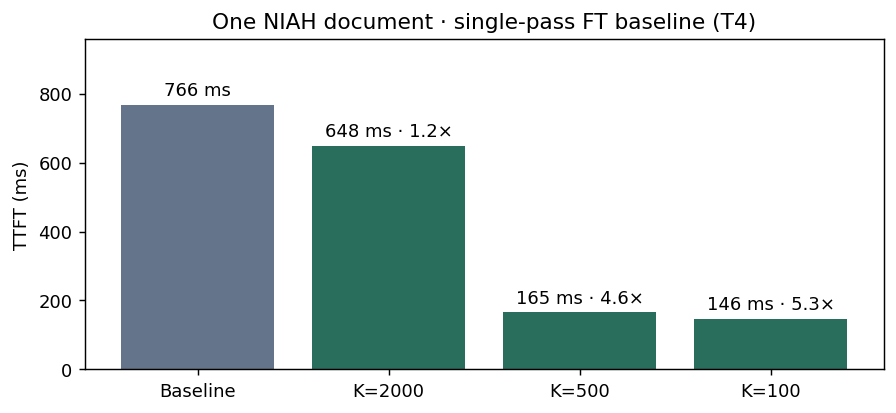

In [6]:
#@title Results { display-mode: "form" }
baseline_name = ('chunked FT baseline (T4)' if PLAIN_CHUNK_TOKENS
                 else f'single-pass FT baseline ({GPU_RUNTIME})')
demo.show_inference_results(plain, gated, baseline_name=baseline_name)


In [7]:
#@title View tokens selected by TokenGate { display-mode: "form" }
VIEW_BUDGET = '10' #@param ['2000', '500', '100', '10']
print('Question:', samples[0]['question'])
print('Needle:', demo.niah_needle(samples[0]))
guided_result = next(r for r in gated if r['budget'] == int(VIEW_BUDGET))
demo.show_kept_tokens(tok, gate_prompts[0], samples[0], guided_result)


Question: What is the best thing to do in Hanoi?
Needle: The best thing to do in Hanoi is share a pot of tea along the canal towpath when the bells ring noon.
Depth 56% · K=10 · kept 10/4,077 document tokens


### Play with the dials

Choose a needle depth, document size, and list of token budgets.
On a T4, Qwen3's full-prefill baseline uses cached chunks above **4k** document tokens to fit memory, so its speedups differ from our paper's single-pass A100 numbers but still show the relative gain.

Question: What is the best thing to do in Amman?
Expected answer: queue for dumplings on the pedestrian bridge at first light
Needle depth: 11%; document: 8,189 tokens
Ordinary-model prefill: chunked FT baseline (T4)


Method,Token budget,Answer,Correct?,TTFT (ms),Peak PyTorch (GiB),Document kept,Total prompt kept
FT baseline,Full,queue for dumplings on the pedestrian bridge at first light,Yes,2402,4.19,All,"8,233"
TokenGate,"2,000",queue for dumplings on the pedestrian bridge at first light,Yes,773,3.81,"2,000 (24.4%)","2,044"
TokenGate,500,queue for dumplings on the pedestrian bridge at first light,Yes,272,3.81,500 (6.1%),544
TokenGate,100,queue for dumplings on the pedestrian bridge at first light,Yes,253,3.81,100 (1.2%),144
TokenGate,10,queue for dumplings on the balcony at first light,No,276,3.81,10 (0.1%),54

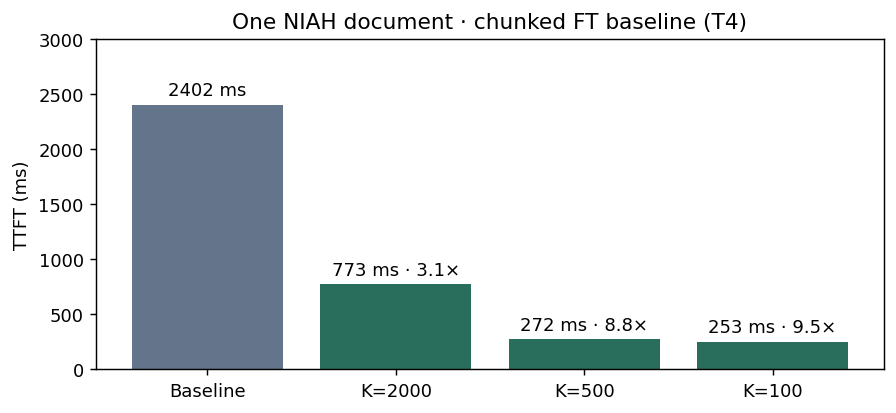

In [8]:
#@title Demo settings { display-mode: "form" }
NEEDLE_DEPTH = 'Start' #@param ['Start', 'Middle', 'End']
DOCUMENT_SIZE = '8k' #@param ['2k', '4k', '8k', '16k']
TOKEN_BUDGETS = '2000, 500, 100, 10' #@param {type:"string"}

selected_index = {'Start': 0, 'Middle': 1, 'End': 2}[NEEDLE_DEPTH]
selected_doc_tokens = int(DOCUMENT_SIZE[:-1]) * 1024
selected_budgets = tuple(int(x.strip()) for x in TOKEN_BUDGETS.split(',') if x.strip())
assert selected_budgets and len(set(selected_budgets)) == len(selected_budgets) and all(k > 0 for k in selected_budgets)
if 'gate' in globals():
    del gate
    gc.collect(); torch.cuda.empty_cache()
import importlib
import demo_helpers
demo_helpers = importlib.reload(demo_helpers)
if getattr(demo_helpers, 'DEMO_CACHE_VERSION', 0) < 2:
    raise RuntimeError('Run Set up the demo environment above, then rerun Demo settings.')
repo_id, revision = CHECKPOINTS[MODEL]
exploration = demo_helpers.run_niah_exploration(
    SOURCE, base_model=BASE_MODEL, checkpoint_id=repo_id,
    checkpoint_revision=revision, baseline_checkpoint=SFT_BASELINES[MODEL],
    gpu_runtime=GPU_RUNTIME,
    doc_tokens=selected_doc_tokens, example_index=selected_index,
    budgets=selected_budgets)


In [9]:
#@title View tokens selected by TokenGate { display-mode: "form" }
import ipywidgets as widgets
from IPython.display import display
import demo_helpers
if 'exploration' not in globals():
    raise RuntimeError('Run Demo settings in this runtime. Saved output does not restore its results.')
if exploration.get('cache_version', 0) < 2 or 'tokenizer' not in exploration or any('kept_pos' not in row for row in exploration['gated']):
    raise RuntimeError('These results predate cached token selections. Rerun setup, then Demo settings.')

print('Question:', exploration['sample']['question'])
print('Needle:', demo_helpers.niah_needle(exploration['sample']))
budget_options = tuple(dict.fromkeys(row['budget'] for row in exploration['gated']))
selected_token_budget = widgets.Dropdown(
    options=[(f'K={k:,}', k) for k in budget_options],
    value=100 if 100 in budget_options else sorted(budget_options)[len(budget_options) // 2],
    description='View selected tokens:',
    style={'description_width': 'initial'})

def render_selected_tokens(token_budget):
    result = next(row for row in exploration['gated'] if row['budget'] == token_budget)
    demo_helpers.show_kept_tokens(exploration['tokenizer'], exploration['gate_prompt'],
                                  exploration['sample'], result)

display(widgets.interactive(render_selected_tokens,
                            token_budget=selected_token_budget))


Question: What is the best thing to do in Amman?
Needle: The best thing to do in Amman is queue for dumplings on the pedestrian bridge at first light.


interactive(children=(Dropdown(description='View selected tokens:', index=2, options=(('K=2,000', 2000), ('K=5…

## 3. Make your model a Token-Gated Language Model

The inference cells use released weights. This path trains a new gate and its paired LoRA adapter on **12,000 NIAH training examples**, uses **50 validation examples**, and reserves **150 test examples**. It then trains a separate LoRA-only full-prefill baseline on the same data and compares both on one held-out question.

Use a runtime with **four A100 GPUs** and enable `RUN_TRAINING` to run the two training cells. The reusable TokenGate pattern is visible in the first one: create a `TokenGateConfig`, pass `{"article": ..., "answer": ...}` rows to `TokenGateTrainer`, and call `trainer.train()`. The recipe helper fills in this demo's NIAH training settings. Expect a long run, especially for Qwen3.5.


In [10]:
#@title Train the gate (four A100s) { display-mode: "form" }
RUN_TRAINING = False #@param {type:"boolean"}
if RUN_TRAINING:
    from tokengate import TokenGateConfig, TokenGateTrainer
    assert GPU_RUNTIME == 'A100', 'Choose A100 above and use a runtime with four A100 GPUs.'
    n_gpus = torch.cuda.device_count()
    assert n_gpus == 4 and all('A100' in torch.cuda.get_device_name(i) for i in range(n_gpus)), 'Use exactly four visible A100 GPUs.'
    gc.collect()
    torch.cuda.empty_cache()
    work = Path('/content/tokengate-training') if Path('/content').is_dir() else Path.cwd()/'tokengate-training'
    work = work/MODEL
    data_root = work/'data'

    # Replace these NIAH rows with your own {"article": text, "answer": text} rows.
    train_rows, eval_rows = demo.release_niah_rows(SOURCE, work)
    recipe = demo.release_niah_config_kwargs(SOURCE, BASE_MODEL, work/'gate', data_root, n_gpus)

    # These three public API calls are the reusable training pattern.
    config = TokenGateConfig(**recipe)
    trainer = TokenGateTrainer(config, train_dataset=train_rows,
                               eval_dataset=eval_rows, task='niah_kamradt')
    gate_checkpoint = Path(config.output_dir)/'gate_final.pt'
    if not gate_checkpoint.exists():
        if MODEL == 'Qwen3-1.7B':
            from kernels.fa2bias.keybias import available as fa2_available
            if not fa2_available():
                subprocess.run([sys.executable, str(SOURCE/'kernels/fa2bias/build.py')], check=True)
        trainer.train()
    del trainer, train_rows, eval_rows
    gc.collect()
    print('Gate checkpoint:', gate_checkpoint)
else:
    print('Optional training skipped; the inference above uses released weights.')


Optional training skipped; the inference above uses released weights.


### Train the comparison model

The gate's paired LoRA adapter is part of the TokenGate model. For a fair full-prefill comparison, this next cell trains a **separate LoRA-only baseline** on the same NIAH rows and validation split.


In [11]:
#@title Train the separate LoRA baseline (four A100s) { display-mode: "form" }
if RUN_TRAINING:
    baseline_dir = demo.train_demo_sft_baseline(
        BASE_MODEL, data_root, config.eval_split, work/'lora_baseline', n_gpus)
    print('LoRA baseline:', baseline_dir)
else:
    print('Optional training skipped.')


Optional training skipped.


### Compare your trained models

The final cell loads both newly trained models and checks their answers and TTFT on one held-out 16k question. This quick check is smaller than the full evaluation in our paper.


In [12]:
#@title Compare your trained gate with its LoRA baseline (A100) { display-mode: "form" }
if RUN_TRAINING:
    if 'baseline_dir' not in globals():
        raise RuntimeError('Run the separate LoRA baseline cell first.')
    from peft import PeftModel
    benchmark_rows = [demo.niah_examples(SOURCE, 16384)[EXAMPLE_INDEX]]
    pairs = [demo.niah_prompt(tok, row) for row in benchmark_rows]
    trained_gate_prompts, baseline_prompts = map(list, zip(*pairs))
    base = AutoModelForCausalLM.from_pretrained(BASE_MODEL, dtype=torch.bfloat16, attn_implementation='sdpa')
    tuned_base = PeftModel.from_pretrained(base, str(baseline_dir)).merge_and_unload().cuda().eval()
    tuned_plain = demo.plain_results(tuned_base, tok, baseline_prompts, benchmark_rows)
    del tuned_base, base
    gc.collect(); torch.cuda.empty_cache()
    own_gate = load_model(str(gate_checkpoint), gate_attn='fa2' if MODEL == 'Qwen3-1.7B' else 'flex', dtype=torch.bfloat16)
    own = demo.gate_results(own_gate, tok, trained_gate_prompts, benchmark_rows, BUDGETS)
    demo.show_inference_results(tuned_plain, own, baseline_name='newly trained LoRA baseline (A100)')
else:
    print('Run the optional training cell first.')


Run the optional training cell first.
